<a href="https://colab.research.google.com/github/charlesanthony1996/explainable-ai-assignment1/blob/main/lab_track_b_backup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [169]:
#imports

import os
import numpy as np
import pandas as pd

# for training the model
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import train_test_split


# for TreeSHAP explanations
!pip install shap
import shap
import matplotlib.pyplot as plt

In [170]:
# Step 1

In [171]:
# dataset comes from a public github folder. no need to upload everytime the session expires

data_url = "https://raw.githubusercontent.com/charlesanthony1996/human-centered-and-explainable-ai-datasets/refs/heads/main/Loan%20Dataset.csv"

In [172]:
# df = pd.read_csv("Loan Dataset.csv")
df = pd.read_csv(data_url)

target = "Loan_Amount_Requested"

print(df.columns)

financial = [
    "Annual_Income",
    "Monthly_Expenses",
    "Outstanding_Debt",
    "Total_Existing_Loan_Amount",
    "Existing_Loans",
    "Credit_Score",
    "Loan_History",
    "Bank_Account_History",
    "Transaction_Frequency"
]

exployment_frequency = ["Employment_Status", "Monthly_Expenses", "Outstanding_Debt",
                        "Total_Existing_Loan_Amount","Existing_Loans",
                        "Credit_Score", "Loan_History", "Bank_Account_History",
                        "Transaction_Frequency"
                        ]

employment = [
    "Employment_Status", "Occupation_Type",
    "Education"
]

context = [
    "Residential_Status", "City/Town", "Loan_Purpose",
    "Co-Applicant"
]

sensitive = [
    "Gender", "Age", "Marital_Status", "Dependents"
]

Index(['Applicant_ID', 'Gender', 'Age', 'Marital_Status', 'Dependents',
       'Education', 'Employment_Status', 'Occupation_Type',
       'Residential_Status', 'City/Town', 'Annual_Income', 'Monthly_Expenses',
       'Credit_Score', 'Existing_Loans', 'Total_Existing_Loan_Amount',
       'Outstanding_Debt', 'Loan_History', 'Loan_Amount_Requested',
       'Loan_Term', 'Loan_Purpose', 'Interest_Rate', 'Loan_Type',
       'Co-Applicant', 'Bank_Account_History', 'Transaction_Frequency',
       'Default_Risk', 'Loan_Approval_Status'],
      dtype='object')


In [173]:
# creating a new column here

df["Household_Size"] = 1 + (df["Marital_Status"] == "Married").astype(int) + df["Dependents"]
sensitive.append("Household_Size")

In [174]:
excluded = ["Applicant_ID", "Loan_Approval_Status", "Interest_Rate", "Default_Risk", "Loan_Term", "Loan_Type"]

features_all = financial + employment + context + sensitive

features_no_sensitive = financial + employment + context

In [175]:
out = df[features_all + [target]].copy()

out.to_csv("loan_inputs_prepared.csv", index=False)

In [176]:
# Step 2

In [177]:
# 2. train the model

seed = 42

df = pd.read_csv("loan_inputs_prepared.csv")

In [178]:
# ordinal encode categoricals so each original feature stays one column
# trees dont need one hot and it keeps shap plots in step 3 readable
# one bar per feature instead of one per category

categorical = df[features_all].select_dtypes(exclude="number").columns.tolist()
print(categorical)

category_maps = {}

for col in categorical:

  df[col] = df[col].astype("category")

  category_maps[col] = dict(enumerate(df[col].cat.categories))

  df[col] = df[col].cat.codes

x = df[features_all]
y = df[target]

x_train, x_test , y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=seed)

['Employment_Status', 'Occupation_Type', 'Education', 'Residential_Status', 'City/Town', 'Loan_Purpose', 'Co-Applicant', 'Gender', 'Marital_Status']


In [179]:
# min_samples_leaf keeps the trees from memorising single applicants and
# keeps the model small enough for fast TreeSHAP later


# max_features -> ?
model = RandomForestRegressor(
    n_estimators = 300,
    min_samples_leaf=10,
    max_features=0.5,
    n_jobs=-1,
    random_state=seed
)

model.fit(x_train, y_train)

RandomForestRegressor(max_features=0.5, min_samples_leaf=10, n_estimators=300,
                      n_jobs=-1, random_state=42)

In [180]:
def report(name, est):

  pred = est.predict(x_test)

  r2 = r2_score(y_test, pred)
  mae = mean_absolute_error(y_test, pred)
  mse = mean_squared_error(y_test, pred)
  rmse = np.sqrt(mse)

  print(f"R2 Score={r2:.3f}")
  print(f"MAE Score = {mae:,.0f}")
  print(f"RMSE Score = {rmse:,.0f}")

In [181]:
# a baseline model that always predicts the average loan amount
baseline_model = DummyRegressor()
baseline_model.fit(x_train, y_train)
report("Baseline (mean): ", baseline_model)

print()
# the random forest
report("Random forest: ", model)


print()
# overfitting check: compare train R2 with test R2
train_r2 = model.score(x_train, y_train)
print(f"Train R2 = {train_r2:.3f}")


R2 Score=-0.000
MAE Score = 6,115
RMSE Score = 8,165

R2 Score=0.777
MAE Score = 2,759
RMSE Score = 3,856

Train R2 = 0.856


In [182]:
# Step 3: TreeSHAP explanations

In [183]:
# TreeExplainer uses the exact TreeSHAP algorithm for tree models
explainer = shap.TreeExplainer(model)

# explaining all 10,400 test rows is slow, so use a random sample of 1000
x_sample = x_test.sample(n=100, random_state=seed)

# compute the SHAP values
shap_explanation = explainer(x_sample)
print(shap_explanation)

# the baseline is the model's average prediction (the starting point of every explanation)
all_base_values = shap_explanation.base_values
baseline = float(all_base_values[0])
print(f"Baseline (average prediction): {baseline:,.0f}")

.values =
array([[-1.89275922e+02, -1.12861543e+01, -2.51589703e+01, ...,
         2.90453069e+01,  1.81446730e+01,  3.28777919e+00],
       [ 2.81165621e+03,  8.35548945e+01, -6.88404709e+01, ...,
        -1.16048069e+01,  1.14527973e+00, -4.36514857e+01],
       [-4.06601135e+03, -5.08011444e+01, -3.58080655e+01, ...,
        -2.15384022e+00, -2.23535099e+01,  7.20328932e+00],
       ...,
       [-3.63698458e+03, -1.29352281e+01,  7.90680355e+00, ...,
        -6.30007219e+00, -7.98116102e+00, -5.93732382e-01],
       [ 5.85859382e+03, -8.55818415e+01,  9.22585492e+01, ...,
         8.63869485e+00,  5.72800138e+00,  1.81741252e+00],
       [-7.12884836e+02, -7.65151020e+00, -3.34941824e+01, ...,
         2.50191706e+01,  1.08546000e+01,  5.34554397e+00]],
      shape=(100, 21))

.base_values =
array([21077.55912772, 21077.55912772, 21077.55912772, 21077.55912772,
       21077.55912772, 21077.55912772, 21077.55912772, 21077.55912772,
       21077.55912772, 21077.55912772, 21077.5591277

In [184]:
# turn the category codes back into labels, so the waterfall shows
# "Employed" instead of "1"
x_sample_readable = x_sample.copy()

for col in categorical:

  codes = x_sample_readable[col]
  code_to_label = category_maps[col]
  labels = codes.map(code_to_label)
  x_sample_readable[col] = labels


shap_explanation.display_data = x_sample_readable.values

In [185]:
# pick one applicant for the waterfall plot
applicant_index = 0
applicant_explanation = shap_explanation[applicant_index]

applicant_row = x_sample.iloc[[applicant_index]]
applicant_prediction = model.predict(applicant_row)[0]
print(f"predicted loan amount for applicant {applicant_index}: {applicant_prediction:,.0f}")

predicted loan amount for applicant 0: 23,248


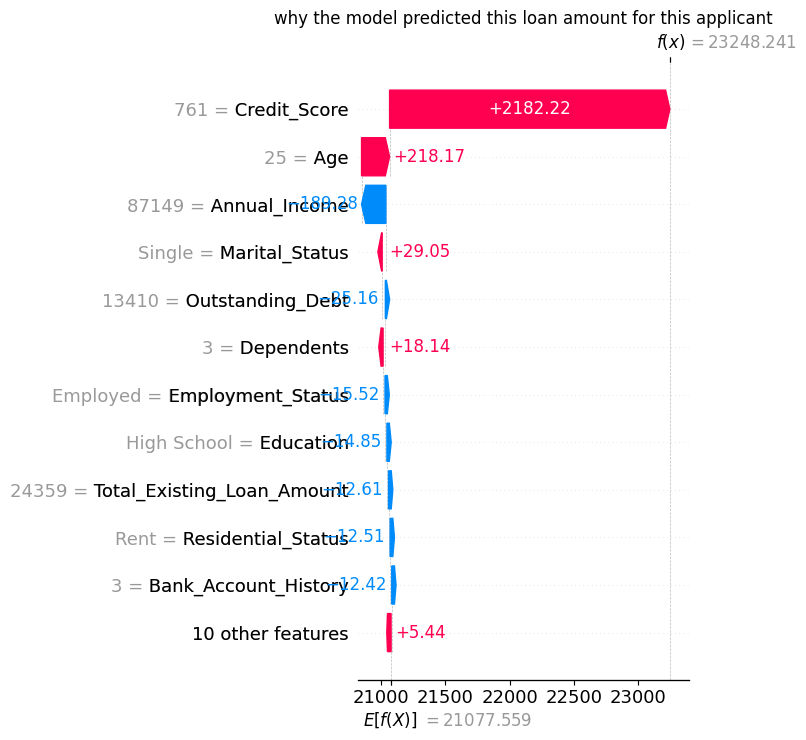

In [186]:
# local plot: waterfall for one applicant
shap.plots.waterfall(applicant_explanation, max_display=12, show=False)
plt.title("why the model predicted this loan amount for this applicant")
plt.tight_layout()
plt.show()

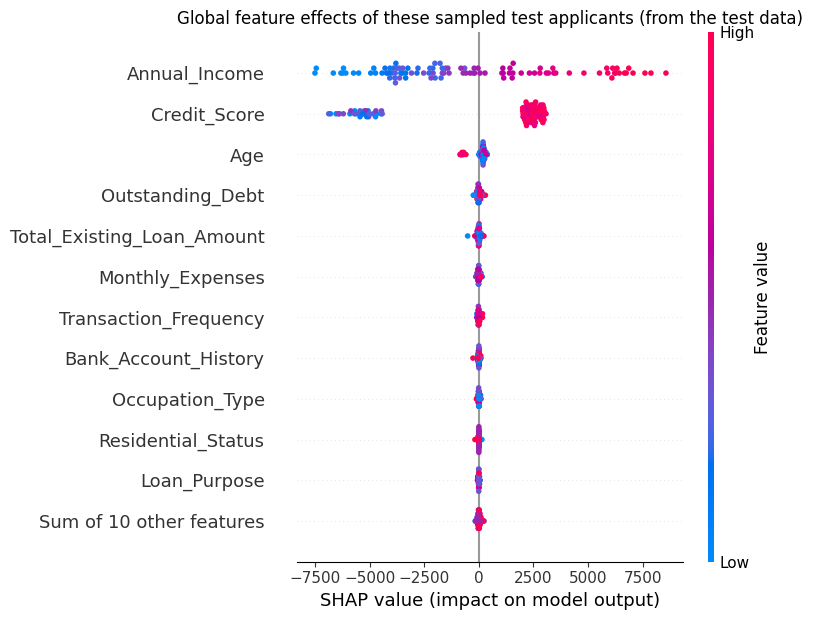

In [187]:
# global plot: beeswarm over the sampled applicants
shap.plots.beeswarm(shap_explanation, max_display=12, show=False)
plt.title("Global feature effects of these sampled test applicants (from the test data)")
plt.tight_layout()
plt.show()

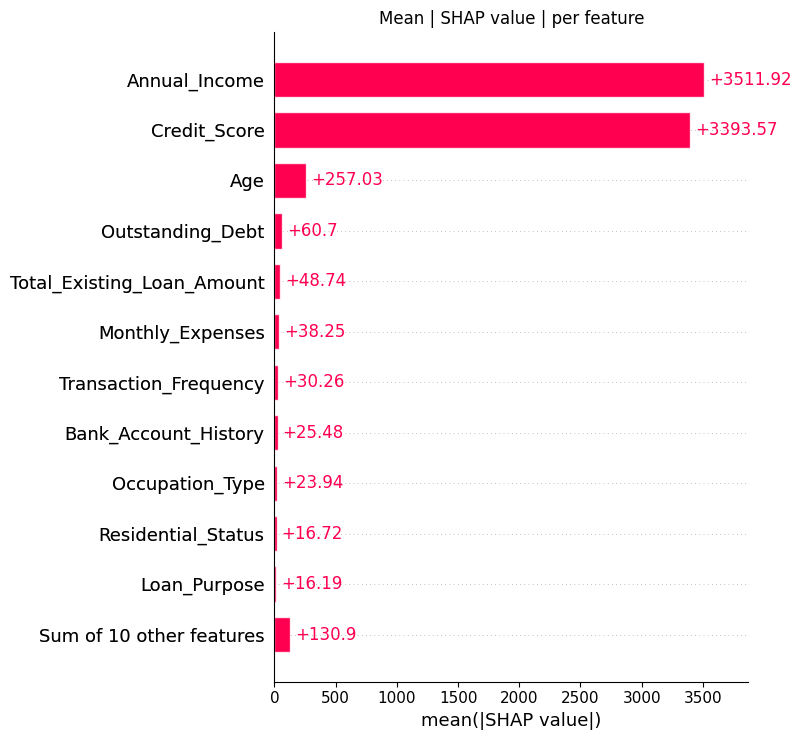

In [188]:
# showing the bar plot as well here
shap.plots.bar(shap_explanation, max_display=12, show=False)
plt.title("Mean | SHAP value | per feature")
plt.tight_layout()
plt.show()

In [189]:
# Step 4 verify that baseline + contributions = prediction

# check the one applicant from the waterfall plot

applicant_explanation = shap_explanation[applicant_index]

applicant_baseline = float(applicant_explanation.base_values)
applicant_contributions = applicant_explanation.values
sum_of_contributions = applicant_contributions.sum()

reconstructed_prediction = applicant_baseline + sum_of_contributions

applicant_row = x_sample.iloc[[applicant_index]]
model_prediction = model.predict(applicant_row)[0]

difference = abs(reconstructed_prediction - model_prediction)

print(f"Baseline: ", {applicant_baseline})
print(f"Sum of SHAP contributions: {sum_of_contributions}")
print(f"Baseline + contributions: {reconstructed_prediction}")
print(f"Model prediction:  {model_prediction}")
print(f"Absolute difference: {difference}")


Baseline:  {21077.559127724362}
Sum of SHAP contributions: 2170.681637539589
Baseline + contributions: 23248.240765263952
Model prediction:  23248.240765263996
Absolute difference: 4.3655745685100555e-11


In [190]:
# floating point sums are never exactly equal, so compare within a tolerance
tolerance = 1e-6

applicant_matches = np.isclose(reconstructed_prediction, model_prediction, rtol=0, atol=tolerance)
print(f"Matches within tolerance {tolerance}: {applicant_matches}")

Matches within tolerance 1e-06: True


In [191]:
# check all 1000 sampled applicants at once

all_contributions_sums = shap_explanation.values.sum(axis =1)
all_reconstructed = shap_explanation.base_values + all_contributions_sums

all_predictions = model.predict(x_sample)
# print(all_predictions)

all_differences = np.abs(all_reconstructed - all_predictions)
largest_difference = all_differences.sum()

print("largest difference: ", largest_difference)

all_match = np.allclose(all_reconstructed, all_predictions, rtol =0, atol=tolerance)

print(f"largest difference across applicants: {largest_difference:.2e}")
print(f"All applicants match within tolerance: {all_match}")

largest difference:  8.386450645048171e-09
largest difference across applicants: 8.39e-09
All applicants match within tolerance: True


In [192]:
# step 5: compare results with and without sensitive demographic inputs

# 5a train a second model without the sensitive features

x_train_ns = x_train[features_no_sensitive]
x_test_ns = x_test[features_no_sensitive]

# same settings as the first model, so the only difference is the features
model_ns = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=10,
    max_features=0.5,
    n_jobs=-1,
    random_state=seed
)

model_ns.fit(x_train, y_train)

pred_all = model.predict(x_test)
